# 03: Results for the presentation

1. Does the model get better with more houses?
2. How much does 1 kW of solar make in Lahore?
3. What does the calculator recommend for our real houses?
4. How well does the bill OCR read our bills?

Charts are also saved to `reports/figures/` for the slides.

In [1]:
import sys, json, itertools
from pathlib import Path
sys.path.append("../ml-service")

import pandas as pd
import matplotlib.pyplot as plt
from core.data import build_clean, CONFIG
from core.train import evaluate_seasonal, load_seasonal
from core.predict import year_from_bill
from core.solar import plan

FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
cfg = json.loads((CONFIG / "pakistan.json").read_text())
df = build_clean()

## 1. Accuracy vs number of houses

For every group of 2, 3 and 4 houses we train and test the shape model (leaving one house out each time). The error is shown as a percentage of each month's units, so big and small houses count the same.

In [2]:
rows = []
houses = sorted(df["site_id"].unique())
for k in range(2, len(houses) + 1):
    for group in itertools.combinations(houses, k):
        s = evaluate_seasonal(df[df["site_id"].isin(group)], load_seasonal()["base_temp"])
        rows.append({"houses": k, "group": "+".join(group), "error_percent": round(100 * s["mape"], 1), "r2": s["r2"]})
curve = pd.DataFrame(rows)
summary = curve.groupby("houses").agg(avg_error_percent=("error_percent", "mean"), avg_r2=("r2", "mean"), groups=("group", "count")).round(2)
summary

,avg_error_percent,avg_r2,groups
houses,,,
2,38.67,0.64,6
3,35.38,0.74,4
4,33.00,0.84,1


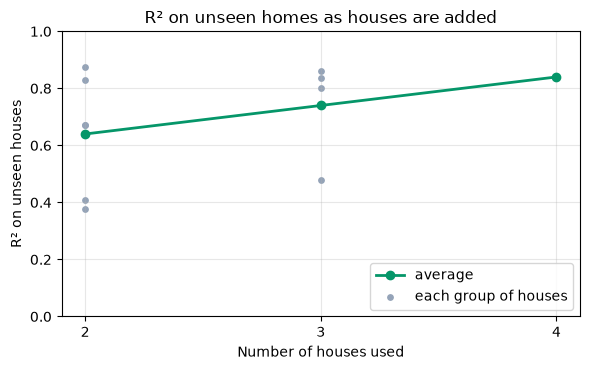

In [3]:
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(summary.index, summary["avg_r2"], "o-", color="#059669", lw=2, label="average")
ax.scatter(curve["houses"], curve["r2"], color="#94a3b8", s=15, zorder=0, label="each group of houses")
ax.set_xticks(summary.index); ax.set_ylim(0, 1)
ax.set_xlabel("Number of houses used")
ax.set_ylabel("R² on unseen houses")
ax.set_title(f"R² on unseen homes as houses are added")
ax.grid(alpha=0.3); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIG / "accuracy_vs_houses.png", dpi=150); plt.show()

**Honest reading:** see the table above for the exact numbers. Only 4 houses is a short curve; it should be re-run as bills come in, and `models/history.csv` logs every retrain for that.

## 2. Solar output in Lahore (real data, H003, 10 kW)

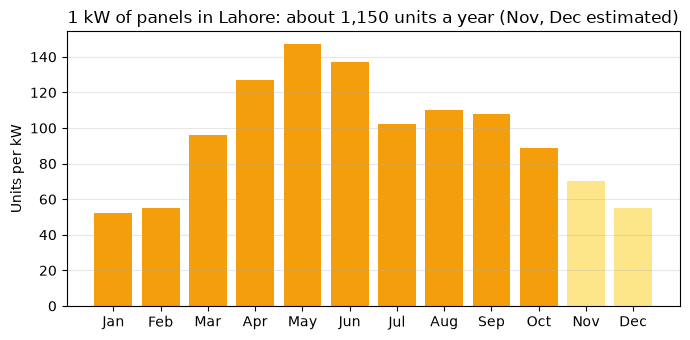

Year total: 1148 units per kW | Jan is 35 % of May (smog and short days)


In [4]:
yld = cfg["solar"]["yield_per_kw_month"]
months = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
vals = [yld[str(i)] for i in range(1, 13)]
colors = ["#f59e0b"] * 10 + ["#fde68a"] * 2
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(months, vals, color=colors)
ax.set_ylabel("Units per kW")
ax.set_title("1 kW of panels in Lahore: about 1,150 units a year (Nov, Dec estimated)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(FIG / "solar_per_kw.png", dpi=150); plt.show()
print("Year total:", sum(vals), "units per kW | Jan is", round(vals[0] / vals[4] * 100), "% of May (smog and short days)")

## 3. Calculator results for our 4 clean houses

In [5]:
roofs = {"H004": 5000, "H005": 450, "H006": 450, "H007": 900}   # rough free roof area (sq ft)
out = []
for site, g in df.groupby("site_id"):
    last12 = g.sort_values(["year", "month"]).tail(12)
    year, _ = year_from_bill({int(r.month): r.units for r in last12.itertuples()})
    load = float(last12["sanctioned_load_kw"].iloc[-1])
    p = plan({m: v["units"] for m, v in year.items()}, roofs[site], "concrete", load, cfg)
    r, b = p["recommended"], p["with_battery"]
    out.append({"house": site, "units/year": p["yearly_units"], "panels": r["panels"], "kW": r["kw"],
                "cost (Rs)": f"{r['cost']:,}", "saving/month (Rs)": f"{r['monthly_saving']:,}",
                "payback (yrs)": r["payback_years"], "with battery payback": b["payback_years"]})
pd.DataFrame(out)

,house,units/year,panels,kW,cost (Rs),saving/month (Rs),payback (yrs),with battery payback
0,H004,12700,12,7.02,"744,980","25,815",2.4,5.1
1,H005,2927,6,3.51,"397,490","8,505",3.9,6.2
2,H006,2062,4,2.34,"301,460","5,685",4.4,5.8
3,H007,2548,5,2.92,"341,480","6,889",4.1,6.6


## 4. Bill OCR accuracy

Run `ml-service/venv/Scripts/python notebooks/ocr_eval.py <folder with the bill photos>`. Result on our 6 bill photos (11 November 2026):

| Bill | Months read correctly |
|---|---|
| H005, H006 (clean online bills) | 12/12 and 12/12 |
| H001, H007 (phone photos) | 9/12 and 6/12 |
| H003, H004 (tilted, faded photos) | 0/12 |
| **Total** | **39/72 = 54%** |

Two fixes took the clean bills from 9 and 10 months to 12: the barcode line at the bottom of the bill also has month names ("OCT 26 ... 06 NOV 26"), and it used to overwrite the table's October and November; and a number that cannot be that month's units (for example the bill amount, or "96" read as "6") is now left empty instead of filled in wrongly. Phone photos stay weak, so the app always shows the numbers for the user to check. Setting `ANTHROPIC_API_KEY` switches the app to Claude vision, which reads photos much better (small cost per bill).